# 00. labeled 베이스 테이블 (EDA용 · labeled_data.csv 전체 기준)

**목표**: 1차 원본 `labeled_data.csv`의 CN7·RG3 전체를 정리하고, 대회 2차 파일(`moldset_labeled_cn7/rg3.csv`)에 해당하는 행을 표시해 **EDA·파생변수 작업의 공통 베이스**를 만든다.

| 단계 | 내용 |
|---|---|
| 1 | 1차 원본 정리 (CN7·RG3·650톤 설비만, 완전 중복 제거, 라벨 변환) |
| 2 | 2차 범위 행 찾기 → **z-score 재현·라벨 일치 검증** → `in_secondary`, `sec_index` 표시 |
| 3 | 전체 행에 **2차 기준 z-score** 계산 (2차 행은 대회 값과 동일, 추가 기간도 같은 기준) |
| 4 | 같은 `TimeStamp`의 LH·RH 두 행 → **샷 1행** |
| 5 | 제품별 시간순으로 **Run(연속 가동 구간)** 구분 → `split` 부여 |

**데이터 운영 원칙** (팀 합의)
- EDA는 전체로 보되, 모든 그래프에서 `split`(2차 / 추가)을 구분해서 표시
- 가설·파생변수 판단은 **2차에서 보인 패턴** 기준 → 추가 기간은 **확인·시점 외 검증·오경보 분석** 용도 (학습 미사용)
- `Reason*`, `LH_fail`, `RH_fail`, `fail_pattern` → **모델 입력 금지** (검사 후 정보)

**산출물** (`./base/`)
- `cn7_shots.csv`, `rg3_shots.csv` : **샷 1행, 제품별 (주 분석용)**
- `base_rows.csv` : 제품 1개 = 1행 (LH/RH 따로, 2차 파일 행 번호 `sec_index` 포함 → 제출 형식으로 되돌릴 때)
- `base_runs.csv` : Run 요약
- `base_excluded_shots.csv` : 제외한 이상 기록

## 1. 설정

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager

# ---- 경로 (notebooks 폴더 기준) ----
PRIMARY_PATH = '../../1. 사출성형기 AI 데이터셋/dataset/labeled_data.csv'   # 1차 원본
SECONDARY_DIR = '../data'                                                   # 대회 2차 파일
OUT_DIR = './base'

# ---- 2차 범위 = 생산계획일 (행 수·z-score 재현·라벨 일치로 확인한 조합) ----
SECONDARY_PLAN_DATES = {
    'cn7': ['2020-10-16', '2020-10-20'],
    'rg3': ['2020-10-21', '2020-10-22', '2020-10-23'],
}
EQUIP = '650톤-우진2호기'

# ---- Run 구분 기준 ----
RUN_GAP_MIN = 60    # 직전 샷과 간격이 이 시간(분)보다 길면 새 Run (팀 기준)
STOP_GAP_MIN = 5    # 이보다 길면(RUN_GAP_MIN 이하) 같은 Run 안의 '짧은 정지'
MIN_RUN_SHOTS = 10  # 이보다 샷이 적은 Run은 split='제외' (Run으로 보기 어려움)
MIN_CYCLE_SEC = 50  # 앞/뒤 샷과 이보다 가까우면 별도 샷일 수 없음 (정상 사이클 ≈ 60초)
CYCLE_DEV_SEC = 2   # 그중 Cycle_Time이 그날 중앙값과 이보다 차이 나면 끼어든 이상 기록으로 제외

INITIAL_REASON = '초기허용불량'   # 공정 불량과 성격이 다른 불량 (가동 초기 세팅 중 허용된 폐기)

# ---- 샷 파일(제품별)에서 뺄 공정변수 ----
DROP_VARS = {
    'Clamp_Open_Position': '두 제품 모두 상수',
    'Average_Screw_RPM': '앞 기간 10배 기록(소수점) + 뒤 기간 자릿수 감소로 상수 → 기간 비교 불가, 2차 안에서도 값 2~4개',
    'Max_Back_Pressure': 'Average_Back_Pressure와 상관 0.94 (중복), 전 기간 Max < Avg로 이름과 정의가 다름',
}

os.makedirs(OUT_DIR, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']

_av = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _f in _av:
        mpl.rcParams['font.family'] = _f; break
mpl.rcParams.update({'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)

## 2. 1차 원본 정리

- **제품·설비 필터**: SP2·JX1 제품, 다른 설비(1800TON 등) 행 제거
- **완전 중복 제거**: CN7 10-27 이후는 같은 행이 `_id`만 다르게 2번씩 들어 있음 → `_id` 제외 전체 컬럼 기준. `keep='first'`로 **원래 행 순서 유지** (2차와 순서로 연결하기 때문)
- **라벨**: 원본 `Y`=양품 → 0, `N`=불량 → 1 (2차 파일과 같은 기준)
- **Average_Screw_RPM 소수점 보정**: CN7 10-27까지·RG3 10-23까지는 약 292로, 이후는 약 29로 기록 → 정확히 10배 차이, 같은 시점에 다른 변수(Max_Screw_RPM 약 30.7 등)는 변화 없음, ÷10 하면 평균(29.25) ≤ 최대(30.8)로 물리적으로 맞음 → **앞 기간이 10배로 기록된 것으로 보고 ÷10 보정**. z-score는 스케일에 영향받지 않으므로 2차 z값은 그대로 유지됨

In [2]:
P = pd.read_csv(PRIMARY_PATH, low_memory=False)
n0 = len(P)
P['product'] = P['PART_NAME'].str[:3].str.lower()
P['cavity'] = P['PART_NAME'].str[-2:]                      # 'LH' / 'RH'
P['plan_date'] = pd.to_datetime(P['PART_FACT_PLAN_DATE'].str[:10])
P['TimeStamp'] = pd.to_datetime(P['TimeStamp'])

P = P[P['product'].isin(PRODUCTS) & (P['EQUIP_NAME'] == EQUIP)]
n1 = len(P)
P = P.drop_duplicates(subset=[c for c in P.columns if c != '_id'], keep='first').reset_index(drop=True)
n2 = len(P)
P['PassOrFail'] = P['PassOrFail'].map({'Y': 0, 'N': 1}).astype(int)
P['Reason'] = P['Reason'].fillna('정상')

# Average_Screw_RPM 소수점 보정 (10배로 기록된 앞 기간 ÷10)
rpm_x10 = P['Average_Screw_RPM'] > 100
print('Average_Screw_RPM ÷10 보정:', P[rpm_x10].groupby('product').size().to_dict(),
      '| 보정 전 범위', P.loc[rpm_x10, 'Average_Screw_RPM'].agg(['min', 'max']).round(1).tolist(),
      '| 이후 기간 값', sorted(P.loc[~rpm_x10, 'Average_Screw_RPM'].round(2).unique().tolist()))
P.loc[rpm_x10, 'Average_Screw_RPM'] = P.loc[rpm_x10, 'Average_Screw_RPM'] / 10

print(f'원본 {n0:,}행 → 제품·설비 필터 {n1:,}행 → 완전 중복 제거 {n2:,}행')
display(P.groupby(['product', P['plan_date'].dt.strftime('%m-%d')])
         .agg(행=('PassOrFail', 'size'), 불량=('PassOrFail', 'sum')).T)

Average_Screw_RPM ÷10 보정: {'cn7': 1839, 'rg3': 1182} | 보정 전 범위 [290.4, 293.9] | 이후 기간 값 [29.0, 29.2, 29.4]
원본 7,996행 → 제품·설비 필터 7,992행 → 완전 중복 제거 5,230행


product     cn7                                 rg3                              
plan_date 10-16 10-20 10-27 10-29 10-30 11-03 10-21 10-22 10-23 11-04 11-05 11-06
행           375   836   628   388   821   926    82   600   500    71     2     1
불량           17     0    10     0     0     1     0    15    10     7     0     0

## 3. 2차 범위 행 찾기 + 검증

2차 파일에는 `TimeStamp`·`_id`가 없어서 키 조인이 불가능 → **2차 범위(생산계획일)로 거른 1차 행을 원래 순서대로 1:1 매칭**하고, 아래 세 가지를 **assert로 검증**한다.

1. 행 수 일치
2. 1차를 같은 방식(해당 행 전체 평균·표준편차, `ddof=0`)으로 표준화했을 때 2차 값과 **1e-6 이내 일치** — 행 집합이 하나라도 다르면 평균·표준편차가 바뀌어 크게 어긋남
3. **행별 라벨 100% 일치** — LH·RH는 공정값이 같아 값만으로 캐비티를 못 가리지만, LH/RH 라벨이 다른 샷까지 일치하면 순서가 보존된 것

검증을 통과하면 2차의 **평균·표준편차(raw 기준)를 저장**해 두고, 4장에서 추가 기간 행에도 같은 기준을 적용한다.

In [3]:
FEATURES = None
P['in_secondary'] = False
P['sec_index'] = np.nan
SCALER = {}   # product -> (mean, std)  2차 행 기준

for p in PRODUCTS:
    sec = pd.read_csv(os.path.join(SECONDARY_DIR, f'moldset_labeled_{p}.csv'))
    if FEATURES is None:
        FEATURES = [c for c in sec.columns if c not in ('Unnamed: 0', 'PassOrFail')]
    mask = (P['product'] == p) & P['plan_date'].isin(pd.to_datetime(SECONDARY_PLAN_DATES[p]))
    prim = P[mask]

    assert len(prim) == len(sec), f'{p}: 행 수 불일치 1차 {len(prim)} vs 2차 {len(sec)}'
    mu, sd = prim[FEATURES].mean(), prim[FEATURES].std(ddof=0)
    z = ((prim[FEATURES] - mu) / sd).fillna(0.0)          # 상수 컬럼(Clamp_Open_Position) → 0
    z_diff = np.abs(z.values - sec[FEATURES].values).max()
    assert z_diff < 1e-6, f'{p}: z-score 재현 실패 (최대 차이 {z_diff})'
    label_ok = (prim['PassOrFail'].values == sec['PassOrFail'].values).mean()
    assert label_ok == 1.0, f'{p}: 라벨 불일치 {label_ok:.3f}'

    P.loc[mask, 'in_secondary'] = True
    P.loc[mask, 'sec_index'] = sec['Unnamed: 0'].values
    SCALER[p] = (mu, sd)
    print(f'[{p}] 2차 {len(sec):,}행 연결 | z-score 최대 차이 {z_diff:.1e} | 라벨 일치 {label_ok:.0%}')

RAW = [f'{c}_raw' for c in FEATURES]

[cn7] 2차 1,211행 연결 | z-score 최대 차이 5.7e-13 | 라벨 일치 100%
[rg3] 2차 1,182행 연결 | z-score 최대 차이 6.9e-13 | 라벨 일치 100%


## 4. 전체 행에 2차 기준 z-score 계산

- `*_raw` : 원래 단위 값 (물리적 파생변수·기간 간 비교용)
- 공정변수 이름 그대로 (예: `Injection_Time`) : **2차 행의 평균·표준편차로 표준화한 값**
  - 2차 행은 대회 제공 값과 **동일** (아래에서 재확인)
  - 추가 기간 행도 같은 기준으로 변환 → 따로 표준화하면 기간마다 기준이 달라져 비교 불가

In [4]:
for c in FEATURES:
    P[f'{c}_raw'] = P[c]
for p in PRODUCTS:
    mu, sd = SCALER[p]
    m = P['product'] == p
    z = (P.loc[m, RAW].values - mu.values) / sd.replace(0, np.nan).values
    P.loc[m, FEATURES] = np.nan_to_num(z, nan=0.0)          # 상수 컬럼 → 0 (2차와 동일)

# 재확인: 2차 행의 z값이 대회 파일과 같은지
for p in PRODUCTS:
    sec = pd.read_csv(os.path.join(SECONDARY_DIR, f'moldset_labeled_{p}.csv'))
    got = P[(P['product'] == p) & P['in_secondary']][FEATURES].values
    assert np.abs(got - sec[FEATURES].values).max() < 1e-6
print('2차 행 z값 = 대회 파일 값 ✔')

2차 행 z값 = 대회 파일 값 ✔


In [5]:
ROW_COLS = (['product', 'TimeStamp', 'plan_date', 'cavity', 'PassOrFail', 'Reason',
             'in_secondary', 'sec_index', '_id'] + FEATURES + RAW)
R = P[ROW_COLS].copy()
display(R[R['PassOrFail'] == 1].pivot_table(index=['product', 'Reason'], columns=['in_secondary', 'cavity'],
                                             values='PassOrFail', aggfunc='size', fill_value=0))

cavity          LH  RH  LH  RH
product Reason                
cn7     가스       0   0   3  10
        미성형      1   0   1   3
        초기허용불량   5   5   0   0
rg3     가스       3   2   0  17
        미성형      2   0   0   8

## 5. 샷 단위로 합치기 (LH·RH 2행 → 1행)

- 같은 `product` + `TimeStamp` = 한 번의 사출(샷). **두 행의 공정값이 완전히 같은지 assert로 확인** 후 한 행만 남김
- 2행으로 두면: 같은 X에 라벨이 0/1로 갈리고, 랜덤 split 시 누수가 생기며, Run 내부 변화량(diff·rolling)이 LH→RH 사이에서 0이 되어 깨짐
- 캐비티 정보는 버리지 않고 컬럼으로 보존 (RG3 불량은 전부 RH)
- `PassOrFail_process` : 초기허용불량을 **제외한** 공정 불량 라벨 (초기허용불량은 가동 초기 세팅 중 허용된 폐기로 성격이 다름)

In [6]:
R['shot_key'] = R['product'] + '_' + R['TimeStamp'].dt.strftime('%Y%m%d%H%M%S')
g = R.groupby('shot_key')

dup_cav = g['cavity'].agg(lambda s: s.duplicated().any())
assert not dup_cav.any(), f'같은 샷에 같은 캐비티가 2번: {dup_cav[dup_cav].index.tolist()[:5]}'
n_diff = int(g[RAW].nunique().gt(1).any(axis=1).sum())
assert n_diff == 0, f'LH·RH 공정값이 다른 샷 {n_diff}개 → 한 행으로 합치면 정보 손실'

def per_cav(col, cav):
    return R[R['cavity'] == cav].set_index('shot_key')[col]

S = g[['product', 'TimeStamp', 'plan_date'] + FEATURES + RAW].first()
S['in_secondary'] = g['in_secondary'].all()
S['n_rows'] = g.size()
S['cavities'] = g['cavity'].agg(lambda s: '+'.join(sorted(s)))
S['LH_fail'] = per_cav('PassOrFail', 'LH')
S['RH_fail'] = per_cav('PassOrFail', 'RH')
S['Reason_LH'] = per_cav('Reason', 'LH')
S['Reason_RH'] = per_cav('Reason', 'RH')
S['sec_index_LH'] = per_cav('sec_index', 'LH')
S['sec_index_RH'] = per_cav('sec_index', 'RH')

# 샷 라벨: LH·RH 중 하나라도 불량이면 1
S['PassOrFail'] = S[['LH_fail', 'RH_fail']].max(axis=1).astype(int)
lh, rh = S['LH_fail'].fillna(0).astype(int), S['RH_fail'].fillna(0).astype(int)
S['fail_pattern'] = np.select([(lh == 1) & (rh == 1), lh == 1, rh == 1], ['양쪽', 'LH만', 'RH만'], '정상')

# 통합 불량원인: 같으면 하나, 다르면 '가스+미성형'
def merge_reason(row):
    rs = sorted({r for r in (row['Reason_LH'], row['Reason_RH']) if isinstance(r, str) and r != '정상'})
    return '+'.join(rs) if rs else '정상'
S['Reason'] = S.apply(merge_reason, axis=1)
S['PassOrFail_process'] = ((S['PassOrFail'] == 1) & (S['Reason'] != INITIAL_REASON)).astype(int)
S = S.reset_index()

print(f'{len(R):,}행 → {len(S):,}샷')
print('캐비티 구성:', S.groupby('product')['cavities'].value_counts().to_dict())
display(S.groupby(['product', 'in_secondary', 'fail_pattern']).size().unstack(fill_value=0))
display(S[S['PassOrFail'] == 1].groupby(['product', 'in_secondary', 'Reason']).size().rename('불량 샷').to_frame())

5,230행 → 2,624샷
캐비티 구성: {('cn7', 'LH+RH'): 1979, ('cn7', 'RH'): 10, ('cn7', 'LH'): 6, ('rg3', 'LH+RH'): 627, ('rg3', 'RH'): 1, ('rg3', 'LH'): 1}


fail_pattern          LH만  RH만  양쪽    정상
product in_secondary                    
cn7     False           1    0   5  1383
        True            1   10   3   592
rg3     False           5    2   0    31
        True            0   25   0   566

불량 샷
product in_secondary Reason      
cn7     False        미성형        1
                     초기허용불량     5
        True         가스        11
                     가스+미성형     2
                     미성형        1
rg3     False        가스         5
                     미성형        2
        True         가스        17
                     미성형        8

## 6. Run(연속 가동 구간) 구분

- **날짜가 아니라 실제 가동 흐름 기준**: 날짜로 자르면 자정을 넘는 가동(CN7 10-19 23:24 ~ 10-20 06:20)이 쪼개지고, 하루 안의 긴 정지는 못 잡음
- 제품별 시간순 정렬 → 직전 샷과의 간격(`prev_gap_sec`)이 `RUN_GAP_MIN`분 초과면 새 Run. 정상 사이클은 약 60초
- `STOP_GAP_MIN`분 초과 ~ `RUN_GAP_MIN`분 이하 = 같은 Run 안의 **짧은 정지** (`after_stop`)
- **이상 기록 제외**: 앞/뒤 샷과 `MIN_CYCLE_SEC`초 미만으로 붙어 있고(실제 별도 샷일 수 없는 간격) Cycle_Time이 그날 중앙값과 `CYCLE_DEV_SEC`초 넘게 다른 기록 → 다른 조건(사이클 약 64초)의 기록이 끼어든 것으로 보고 Run 계산 전에 제외 (`base_excluded_shots.csv`에 따로 저장). 남겨두면 `prev_gap_sec`이 3초처럼 찍히고 샷 순번이 밀림. CN7 10-29·10-30에서만 발생, 모두 양품
- 기준값 민감도 표: 30분이면 CN7 10-30(약 59분 정지)이 두 Run으로 갈림 → 팀 기준 60분 사용

In [7]:
def assign_runs(df, run_gap_min, stop_gap_min):
    df = df.sort_values(['product', 'TimeStamp']).reset_index(drop=True)
    gap = df.groupby('product')['TimeStamp'].diff().dt.total_seconds()
    new_run = gap.isna() | (gap > run_gap_min * 60)
    df['run_no'] = new_run.groupby(df['product']).cumsum().astype(int)
    df['run_id'] = df['product'] + '_R' + df['run_no'].astype(str)
    df['prev_gap_sec'] = gap.where(~new_run)                    # Run 첫 샷은 NaN
    df['shot_seq_in_run'] = df.groupby('run_id').cumcount() + 1
    df['min_from_run_start'] = (df['TimeStamp'] - df.groupby('run_id')['TimeStamp'].transform('min')).dt.total_seconds() / 60
    df['after_stop'] = df['prev_gap_sec'] > stop_gap_min * 60
    seg = (new_run | df['after_stop']).groupby(df['run_id']).cumsum()
    df['shots_since_stop'] = df.groupby([df['run_id'], seg]).cumcount() + 1
    return df

# 이상 기록 제거: 앞/뒤 샷과 정상 사이클(약 60초)보다 훨씬 가깝게 붙어 있고(= 실제 별도 샷일 수 없음)
# Cycle_Time이 주변 샷과 동떨어진 기록 → 다른 조건(사이클 약 64초, 사출시간 약 11.5초)의 기록이 끼어든 것
# (CN7 10-29·10-30에서만 발생. 대부분 LH/RH 한쪽만 있음)
S = S.sort_values(['product', 'TimeStamp']).reset_index(drop=True)
_gp = S.groupby('product')['TimeStamp'].diff().dt.total_seconds()
_gn = -S.groupby('product')['TimeStamp'].diff(-1).dt.total_seconds()
_near = np.fmin(_gp, _gn) < MIN_CYCLE_SEC
_day_med = S.groupby(['product', S['TimeStamp'].dt.date])['Cycle_Time_raw'].transform('median')
odd = _near & ((S['Cycle_Time_raw'] - _day_med).abs() > CYCLE_DEV_SEC)
print('사이클보다 가깝게 붙은 샷:', int(_near.sum()), '→ 그중 Cycle_Time이 동떨어진 기록:', int(odd.sum()))
ODD = S[odd].copy()
S = S[~odd].reset_index(drop=True)
print(f'이상 로그로 제외한 샷: {len(ODD)}개 (불량 {int(ODD["PassOrFail"].sum())}개)',
      ODD.groupby(['product', ODD['TimeStamp'].dt.strftime('%m-%d')]).size().to_dict())

sens = {m: assign_runs(S.copy(), m, min(STOP_GAP_MIN, m)).groupby('product')['run_id'].nunique()
        for m in [10, 20, 30, 60, 120]}
display(pd.DataFrame(sens).rename_axis(columns='RUN_GAP_MIN(분)'))

S = assign_runs(S, RUN_GAP_MIN, STOP_GAP_MIN)

# split: 2차 / 추가 / 제외(샷이 너무 적은 Run)
run_size = S.groupby('run_id')['shot_key'].transform('size')
run_sec = S.groupby('run_id')['in_secondary'].transform('all')
assert (S.groupby('run_id')['in_secondary'].nunique() == 1).all(), '2차·추가가 섞인 Run 존재'
S['split'] = np.where(run_size < MIN_RUN_SHOTS, '제외', np.where(run_sec, '2차', '추가'))

gaps = S['prev_gap_sec'].dropna()
print('샷 간격(초):', gaps.describe(percentiles=[.5, .9, .99]).round(1).to_dict())

사이클보다 가깝게 붙은 샷: 44 → 그중 Cycle_Time이 동떨어진 기록: 16
이상 로그로 제외한 샷: 16개 (불량 0개) {('cn7', '10-29'): 8, ('cn7', '10-30'): 8}


RUN_GAP_MIN(분),10,20,30,60,120
product,,,,,
cn7,11,7,7,6,6
rg3,10,8,8,8,8


샷 간격(초): {'count': 2594.0, 'mean': 64.4, 'std': 78.6, 'min': 57.0, '50%': 60.0, '90%': 62.0, '99%': 121.1, 'max': 3569.0}


### Run 요약

In [8]:
def first_fail(g):
    f = g.loc[g['PassOrFail'] == 1, 'shot_seq_in_run']
    return f.min() if len(f) else np.nan

RUNS = S.groupby('run_id').apply(lambda g: pd.Series({
    'product': g['product'].iloc[0],
    'split': g['split'].iloc[0],
    '시작': g['TimeStamp'].min(), '끝': g['TimeStamp'].max(),
    '길이(분)': round((g['TimeStamp'].max() - g['TimeStamp'].min()).total_seconds() / 60),
    '샷': len(g), '불량 샷': int(g['PassOrFail'].sum()),
    '불량률': round(g['PassOrFail'].mean(), 3),
    '불량 유형': ', '.join(f'{k} {v}' for k, v in g.loc[g['PassOrFail'] == 1, 'Reason'].value_counts().items()),
    'LH/RH 불량': f"{int(g['LH_fail'].fillna(0).sum())}/{int(g['RH_fail'].fillna(0).sum())}",
    '짧은 정지': int(g['after_stop'].sum()),
    '첫 불량 샷 순번': first_fail(g),
    '생산계획일': ', '.join(sorted(g['plan_date'].dt.strftime('%m-%d').unique())),
}), include_groups=False).sort_values(['product', '시작'])
display(RUNS)
display(RUNS.groupby(['product', 'split']).agg(Run=('샷', 'size'), 샷=('샷', 'sum'), 불량샷=('불량 샷', 'sum')))

,product,split,시작,끝,길이(분),샷,불량 샷,불량률,불량 유형,LH/RH 불량,짧은 정지,첫 불량 샷 순번,생산계획일
run_id,,,,,,,,,,,,,
cn7_R1,cn7,2차,2020-10-16 04:57:47,2020-10-16 08:05:18,188,188,14,0.074,"가스 11, 가스+미성형 2, 미성형 1",4/13,0,25.0,10-16
cn7_R2,cn7,2차,2020-10-19 23:24:46,2020-10-20 06:20:14,415,418,0,0.000,,0/0,0,NaN,10-20
cn7_R3,cn7,추가,2020-10-27 00:10:40,2020-10-27 05:48:36,338,314,5,0.016,초기허용불량 5,5/5,2,27.0,10-27
cn7_R4,cn7,추가,2020-10-29 04:34:20,2020-10-29 07:58:43,204,189,0,0.000,,0/0,1,NaN,10-29
cn7_R5,cn7,추가,2020-10-29 23:25:39,2020-10-30 07:36:02,490,407,0,0.000,,0/0,3,NaN,10-30
cn7_R6,cn7,추가,2020-11-03 00:38:12,2020-11-03 08:19:35,461,463,1,0.002,미성형 1,1/0,0,248.0,11-03
rg3_R1,rg3,2차,2020-10-21 00:16:26,2020-10-21 00:57:37,41,41,0,0.000,,0/0,0,NaN,10-21
rg3_R2,rg3,2차,2020-10-22 00:24:05,2020-10-22 02:20:26,116,103,5,0.049,"가스 4, 미성형 1",0/5,1,28.0,10-22
rg3_R3,rg3,2차,2020-10-22 04:40:26,2020-10-22 08:09:24,209,197,10,0.051,"가스 6, 미성형 4",0/10,0,7.0,10-22


Run     샷  불량샷
product split                
cn7     2차       2   606   14
        추가       4  1373    6
rg3     2차       5   591   25
        제외       2     2    0
        추가       1    36    7

### Run 타임라인 (진한 막대 = 2차, 연한 막대 = 추가 · 빨간 점 = 공정 불량, 주황 점 = 초기허용불량, 세로선 = 짧은 정지)

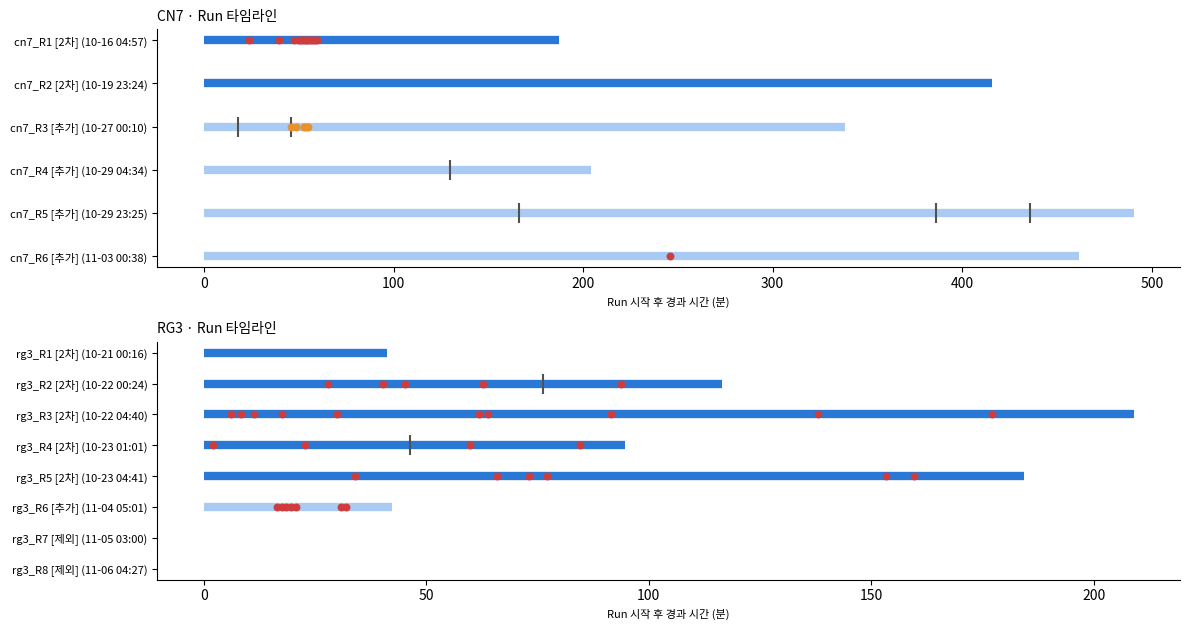

In [9]:
DARK, LIGHT, GRAY, RED, ORANGE = '#2a78d6', '#a9cbf3', '#d6d5cc', '#d03b3b', '#e8912d'
fig, axes = plt.subplots(len(PRODUCTS), 1, figsize=(12, 3.2 * len(PRODUCTS)))
for ax, p in zip(np.atleast_1d(axes), PRODUCTS):
    s = S[S['product'] == p]
    runs = list(dict.fromkeys(s['run_id']))
    for k, r in enumerate(runs):
        g = s[s['run_id'] == r]
        col = {'2차': DARK, '추가': LIGHT, '제외': GRAY}[g['split'].iloc[0]]
        ax.plot(g['min_from_run_start'], np.full(len(g), k), color=col, lw=6, solid_capstyle='butt')
        st = g[g['after_stop']]
        ax.scatter(st['min_from_run_start'], np.full(len(st), k), marker='|', s=200, color='#52514e', zorder=3)
        f = g[g['PassOrFail_process'] == 1]
        ax.scatter(f['min_from_run_start'], np.full(len(f), k), s=22, color=RED, zorder=4)
        fi = g[(g['PassOrFail'] == 1) & (g['PassOrFail_process'] == 0)]
        ax.scatter(fi['min_from_run_start'], np.full(len(fi), k), s=22, color=ORANGE, zorder=4)
    ax.set_yticks(range(len(runs)))
    ax.set_yticklabels([f"{r} [{s[s['run_id'] == r]['split'].iloc[0]}] ({s[s['run_id'] == r]['TimeStamp'].min():%m-%d %H:%M})"
                        for r in runs], fontsize=8)
    ax.set_xlabel('Run 시작 후 경과 시간 (분)', fontsize=8)
    ax.set_title(f'{p.upper()} · Run 타임라인', loc='left', fontsize=10)
    ax.invert_yaxis()
fig.tight_layout(); plt.show()

## 7. 저장

**제품별 샷 파일(`cn7_shots.csv`, `rg3_shots.csv`) 컬럼**

| 구분 | 컬럼 | 모델 입력 |
|---|---|---|
| 식별·Run | `run_id`, `split`, `TimeStamp` | ❌ (`run_id`는 CV 그룹용) |
| Run 위치 | `shot_seq_in_run`, `prev_gap_sec`, `after_stop`, `shots_since_stop` | ✅ 후보 |
| 라벨 | `PassOrFail`, `PassOrFail_process` | 타깃 |
| 불량 정보 | `Reason`, `LH_fail`, `RH_fail` | ❌ EDA 전용 |
| 공정변수 z (21) | 2차 기준 z-score | ✅ |
| 공정변수 raw (21) | 원래 단위 (`*_raw`) | 파생변수 계산용 |

- 샷 파일에서 뺀 컬럼: `shot_key`·`product`(파일로 구분)·`run_no`·`plan_date`·`in_secondary`(= `split=='2차'`)·`fail_pattern`·`Reason_LH/RH`·`min_from_run_start`(≈ 샷 순번)·`n_rows`·`cavities`·`sec_index_LH/RH` → 필요하면 `base_rows.csv`에 있음
- 뺀 공정변수: `DROP_VARS` 참고 (Clamp_Open_Position, Average_Screw_RPM, Max_Back_Pressure)

In [10]:
KEEP_VARS = [c for c in FEATURES if c not in DROP_VARS]
SHOT_COLS = (['run_id', 'split', 'TimeStamp',
              'shot_seq_in_run', 'prev_gap_sec', 'after_stop', 'shots_since_stop',
              'PassOrFail', 'PassOrFail_process', 'Reason', 'LH_fail', 'RH_fail']
             + KEEP_VARS + [f'{c}_raw' for c in KEEP_VARS])
for p in PRODUCTS:
    out = S.loc[S['product'] == p, SHOT_COLS].sort_values('TimeStamp')
    out.to_csv(os.path.join(OUT_DIR, f'{p}_shots.csv'), index=False, encoding='utf-8-sig')
    print(f'저장: {p}_shots.csv', out.shape, '| split별 샷:', out['split'].value_counts().to_dict())
print('제외한 공정변수:', list(DROP_VARS))

# 행 단위 테이블에도 run 정보 붙이기 (캐비티 단위 분석용)
R = R.merge(S[['shot_key', 'run_id', 'split', 'shot_seq_in_run']], on='shot_key', how='left')
R['split'] = R['split'].fillna('이상로그')          # 6장에서 제외한 이상 로그 행
R[['shot_key', 'run_id', 'split', 'shot_seq_in_run'] + ROW_COLS].to_csv(
    os.path.join(OUT_DIR, 'base_rows.csv'), index=False, encoding='utf-8-sig')
RUNS.to_csv(os.path.join(OUT_DIR, 'base_runs.csv'), encoding='utf-8-sig')
ODD.to_csv(os.path.join(OUT_DIR, 'base_excluded_shots.csv'), index=False, encoding='utf-8-sig')
print('저장: base_excluded_shots.csv', ODD.shape)
print('저장: base_rows.csv ', R.shape)
print('저장: base_runs.csv ', RUNS.shape)

저장: cn7_shots.csv (1979, 54) | split별 샷: {'추가': 1373, '2차': 606}
저장: rg3_shots.csv (629, 54) | split별 샷: {'2차': 591, '추가': 36, '제외': 2}
제외한 공정변수: ['Clamp_Open_Position', 'Average_Screw_RPM', 'Max_Back_Pressure']


저장: base_excluded_shots.csv (16, 65)
저장: base_rows.csv  (5230, 61)
저장: base_runs.csv  (14, 13)


## 사용법

```python
S = pd.read_csv('./base/rg3_shots.csv', parse_dates=['TimeStamp'])
S = S[S['split'] != '제외']
VARS = [c for c in S.columns if c + '_raw' in S.columns]   # 공정변수 z 21개

# EDA: 전체로 보되 split으로 구분해서 그리기
# 학습(가설·파생변수 판단): 2차만
tr = S[S['split'] == '2차']
X, y, groups = tr[VARS], tr['PassOrFail'], tr['run_id']
# 시점 외 검증·오경보 분석: 추가
te = S[S['split'] == '추가']
```

**주의**
- `Reason`, `LH_fail`, `RH_fail` → 모델 입력 금지 (EDA·실패 분석용)
- 공정변수 z값은 **2차 기준 스케일**. 추가 기간은 2차 분포에서 벗어나면 |z|가 크게 나올 수 있음 (드리프트 확인 포인트)
- 초기허용불량(CN7 10-27)은 `PassOrFail=1`이지만 `PassOrFail_process=0` → 분석 목적에 맞게 라벨 선택
- Run·샷 순번은 **labeled 샷만으로** 계산한 값. 실제 설비에는 labeled에 없는 샷이 끼어 있을 수 있음 (예: 10-22 첫 Run 구간에 unlabeled에만 있는 샷 10개)